# Fire history (FHX2) in dplPy

Forest **fire-scar history** data records, for each tree and year, whether the
tree was present, whether it was scarred by fire (and in which season), whether
it was injured, and where its pith/bark/inner/outer ring falls. This is *event*
data, not ring widths, and it lives in the **FHX2** (`.fhx`) file format.

dplPy's fire-history layer is a Python port of the R package
[`burnr`](https://doi.org/10.1016/j.dendro.2018.02.005) (Malevich, Guiterman &
Margolis, 2018), validated against it. Everything lives under a single
namespace, **`dpl.fhx`**, so it stays cleanly separated from dplPy's ring-width
functions. This notebook tours it:

1. Reading FHX2 files
2. The `fhx` data model (a plain DataFrame)
3. Series and site statistics
4. Compositing fire years
5. Fire-interval analysis
6. The fire chart (demograph)
7. Superposed epoch analysis (fire–climate)

The example data (`lgr2`, `pgm`, and a PDSI reconstruction) are burnr's own
example datasets, bundled here in `data/`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import dplpy as dpl

pd.set_option("display.max_rows", 12)
DATA = "data" 

## 1. Reading FHX2 files

`dpl.fhx.read()` parses an FHX2 file into a tidy `pandas.DataFrame`: one row per
observed *(year, series)*, with columns `year`, `series`, and `rec_type`. The
`rec_type` is an ordered categorical drawn from a controlled vocabulary (fire
scars and injuries by season, recorder years, pith/bark/inner/outer, estimate).

In [2]:
lgr2 = dpl.fhx.read(f"{DATA}/lgr2.fhx")
lgr2.head(8)

,year,series,rec_type
0,1366,LGR54,inner_year
1,1411,LGR44,inner_year
2,1423,LGR54,unknown_fi
3,1423,LGR44,unknown_fs
4,1424,LGR54,recorder_year
5,1424,LGR44,recorder_year
6,1425,LGR54,recorder_year
7,1425,LGR44,recorder_year


In [3]:
print("series :", lgr2["series"].nunique())
print("years  :", (int(lgr2["year"].min()), int(lgr2["year"].max())))
lgr2["series"].unique()[:8]

series : 26
years  : (1366, 2012)


<StringArray>
['LGR54', 'LGR44', 'LGR47', 'LGR48', 'LGR46', 'LGR41', 'LGR52', 'LGR51']
Length: 8, dtype: str

The `rec_type` categories that actually occur in `lgr2` — recorder years
dominate, with a handful of fire scars (`_fs`), injuries (`_fi`), and the
pith/bark/inner/outer end markers:

In [4]:
lgr2["rec_type"].value_counts()

rec_type
recorder_year       2614
pith_year             19
bark_year             15
outer_year            11
inner_year             7
                    ... 
springdormant_fi       0
earlylw_fs             0
earlylw_fi             0
latelw_fs              0
latelw_fi              0
Name: count, Length: 29, dtype: int64

## 2. The `fhx` data model

An `fhx` object is just a tagged `DataFrame`, so you subset it with ordinary
pandas — there's no special accessor to learn. The namespace adds only the
operations that carry real fire-history meaning: `dpl.fhx.events` (the fire years
per series, by grepping the scar/injury vocabulary) and `dpl.fhx.sort` (reorder
series by year, for plotting). `dpl.fhx.write` round-trips back to disk.

In [5]:
# one series, with its pith -> scars -> outer record -- plain pandas
lgr2[lgr2["series"] == "LGR46"]

,year,series,rec_type
270,1705,LGR46,pith_year
377,1773,LGR46,dormant_fs
381,1774,LGR46,recorder_year
385,1775,LGR46,recorder_year
389,1776,LGR46,recorder_year
...,...,...,...
762,1845,LGR46,recorder_year
766,1846,LGR46,recorder_year
770,1847,LGR46,recorder_year
774,1848,LGR46,recorder_year


In [6]:
# fire-scar years for a few series (add injuries with injury_event=True)
ey = dpl.fhx.events(lgr2)
{s: ey[s].tolist() for s in ("LGR46", "LGR44", "LGR53")}

{'LGR46': [1773, 1786, 1806], 'LGR44': [1423, 1448], 'LGR53': [1806]}

In [7]:
# every observation in 1773 -- a widespread fire year at this site
lgr2[lgr2["year"] == 1773]

,year,series,rec_type
376,1773,LGR48,recorder_year
377,1773,LGR46,dormant_fs
378,1773,LGR52,early_fs
379,1773,LGR51,recorder_year


In [8]:
# write / read round-trip exactly
import os, tempfile
tmp = os.path.join(tempfile.gettempdir(), "lgr2_roundtrip.fhx")
dpl.fhx.write(lgr2, tmp)
rt = dpl.fhx.read(tmp)
cols = ["year", "series", "rec_type"]
rt[cols].astype(str).equals(lgr2[cols].astype(str))

True

## 3. Series and site statistics

`dpl.fhx.stats` summarizes every series (first/last year, span, inner/outer type,
scar/injury/recording counts, and a quick mean interval). `dpl.fhx.summary`,
`dpl.fhx.sample_depth`, and `dpl.fhx.percent_scarred` give site-level views.

In [9]:
dpl.fhx.stats(lgr2)

,series,first,last,years,inner_type,outer_type,number_scars,number_injuries,recording_years,mean_interval
0,LGR54,1366,1482,117,inner_year,outer_year,0,1,60,NaN
1,LGR44,1411,1503,93,inner_year,outer_year,2,0,81,25.0
2,LGR47,1580,1770,191,pith_year,outer_year,0,0,191,NaN
3,LGR48,1701,1804,104,pith_year,outer_year,0,1,53,NaN
4,LGR46,1705,1849,145,pith_year,outer_year,3,0,77,16.5
...,...,...,...,...,...,...,...,...,...,...
21,LGR35,1877,2011,135,pith_year,bark_year,0,0,135,NaN
22,LGR30,1878,2011,134,pith_year,bark_year,0,0,134,NaN
23,LGR26,1884,2011,128,pith_year,bark_year,0,0,128,NaN
24,LGR42,1894,1970,77,pith_year,outer_year,0,0,77,NaN


In [10]:
dpl.fhx.summary(lgr2)

{'number_series': 26,
 'first_year': 1366,
 'last_year': 2012,
 'number_scars': 9,
 'number_injuries': 6}

**Sample depth** — how many series span each year:

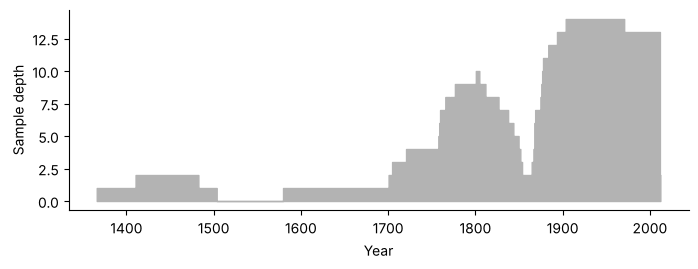

In [11]:
sd = dpl.fhx.sample_depth(lgr2)
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.fill_between(sd["year"], sd["samp_depth"], step="mid", color="0.7")
ax.set_xlabel("Year"); ax.set_ylabel("Sample depth")
for s in ("top", "right"): ax.spines[s].set_visible(False)

**Percent scarred** — of the recording trees each year, how many bore a
scar (shown here only for years with at least one scar):

In [12]:
ps = dpl.fhx.percent_scarred(lgr2)
ps[ps["num_scars"] > 0]

,year,num_rec,num_scars,percent_scarred
0,1423,2,1,50.0
25,1448,2,1,50.0
274,1773,4,2,50.0
287,1786,4,1,25.0
307,1806,8,4,50.0


## 4. Compositing fire years

A **composite** reduces many series to a single site fire chronology: a year is a
composite fire year when a high enough fraction of recording trees scarred
(`filter_prop`, default 0.25), enough trees were recording (`filter_min_rec`,
default 2), and enough events occurred. We switch to the larger **Peggy Mesa
(`pgm`)** collection here.

In [13]:
pgm = dpl.fhx.read(f"{DATA}/pgm.fhx")
comp = dpl.fhx.composite(pgm)                 # burnr defaults: 25%, >=2 recording
comp_years = dpl.fhx.events(comp)["COMP"]
print(len(comp_years), "composite fire years")
comp_years.tolist()

21 composite fire years


[1636,
 1648,
 1664,
 1674,
 1685,
 1714,
 1724,
 1737,
 1746,
 1748,
 1752,
 1782,
 1789,
 1795,
 1798,
 1806,
 1818,
 1824,
 1842,
 1863,
 1871]

Tightening the thresholds (a larger `filter_prop`, more recording trees)
keeps only the more widespread fires:

In [14]:
strict = dpl.fhx.composite(pgm, filter_prop=0.33, filter_min_rec=5)
dpl.fhx.events(strict)["COMP"].tolist()

[1798, 1806, 1818, 1824, 1842]

## 5. Fire-interval analysis

`dpl.fhx.intervals()` takes a one-series composite and analyses the gaps between
successive fire years: observed statistics, a Weibull or lognormal
maximum-likelihood fit, goodness-of-fit tests, and the exceedance-interval
percentiles. It returns a `dpl.fhx.Intervals` object.

In [15]:
iv = dpl.fhx.intervals(comp)
print(iv)

Fire interval analysis
  composite: COMP   events: 1636 to 1871
  intervals: 20   mean: 11.8   median: 10.0   Weibull median: 10.6
  sd: 7.7   min: 2   max: 30
  fit (weibull): shape=1.6565 scale=13.2125
  percentiles  lower(12.5%): 3.9 | median(50%): 10.6 | upper(87.5%): 20.6
  KS D=0.12776 p=0.85948   Shapiro W=0.88485 p=0.02165


In [16]:
print("mean / median / min / max:", iv.mean(), iv.median(), iv.min(), iv.max())
print("Weibull  exceedance (12.5/50/87.5%):", np.round(iv.quantile(), 1))
ivln = dpl.fhx.intervals(comp, densfun="lognormal")
print("lognormal exceedance (12.5/50/87.5%):", np.round(ivln.quantile(), 1))

mean / median / min / max: 11.75 10.0 2 30
Weibull  exceedance (12.5/50/87.5%): [ 3.9 10.6 20.6]
lognormal exceedance (12.5/50/87.5%): [ 4.4  9.5 20.8]


(<Figure size 600x400 with 1 Axes>,
 <Axes: xlabel='Interval (years)', ylabel='Count'>)

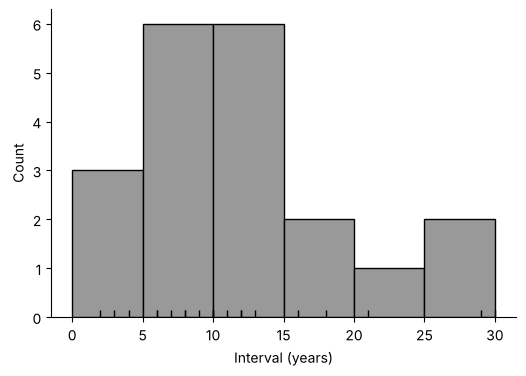

In [17]:
iv.plot(binwidth=5, show=False)

## 6. The fire chart (demograph)

The signature fire-history plot, `dpl.fhx.demograph`: one horizontal line per
series over its span (a dashed non-recording baseline with solid recording
periods on top), fire scars (`|`), injuries (open triangles), and pith/bark years
(dots), with an optional composite **rug** along the bottom. Sorting by first
year gives the classic look.

(<Figure size 1000x750 with 1 Axes>, <Axes: xlabel='Year'>)

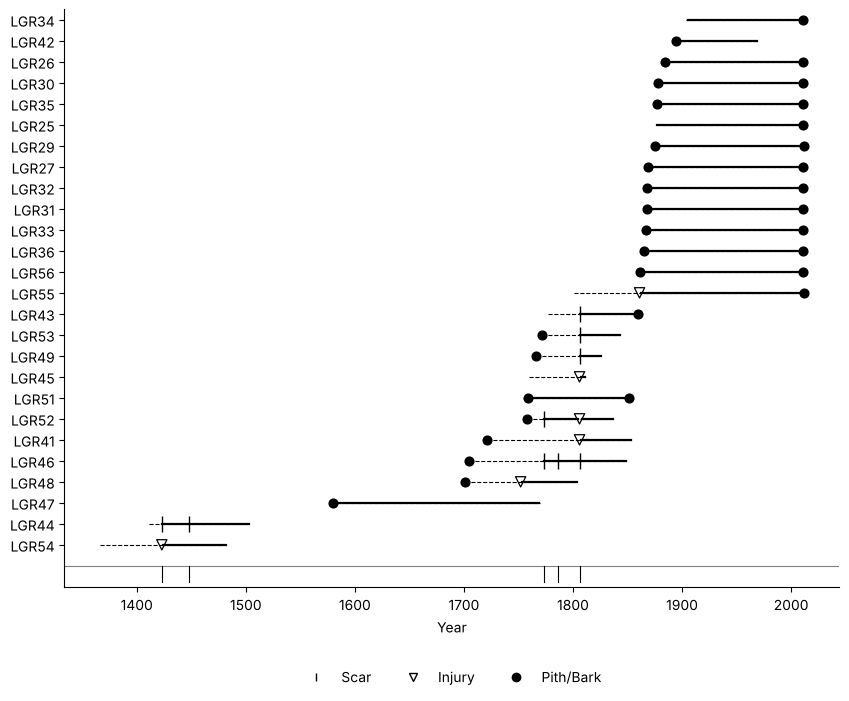

In [18]:
lgr2_sorted = dpl.fhx.sort(lgr2, by="first_year")
dpl.fhx.demograph(lgr2_sorted, composite_rug=True, plot_legend=True, show=False)

`color_group` colours series by any grouping you pass (a dict or Series
keyed by series name) — here, trees that ever recorded a scar vs those that did
not, taken from the `dpl.fhx.stats` table. With 41 series we hide the
y-labels.

(<Figure size 1000x1125 with 1 Axes>, <Axes: xlabel='Year'>)

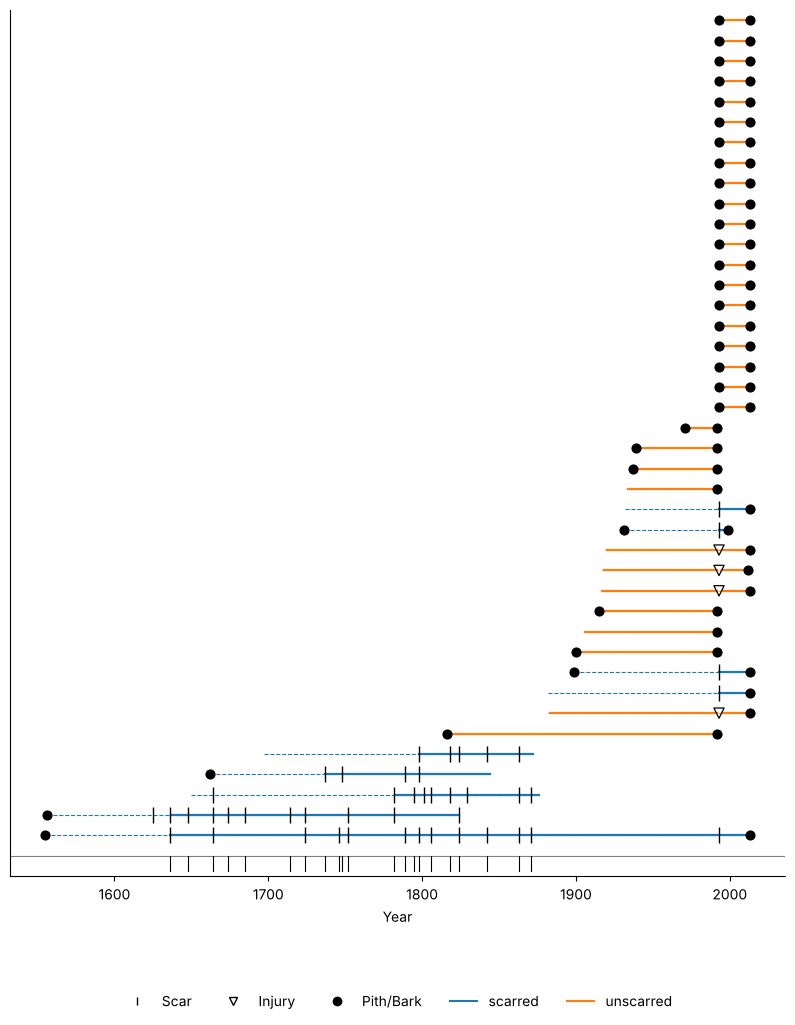

In [19]:
stats = dpl.fhx.stats(pgm).set_index("series")
scarred = {s: ("scarred" if stats.loc[s, "number_scars"] else "unscarred")
           for s in stats.index}
pgm_sorted = dpl.fhx.sort(pgm, by="first_year")
dpl.fhx.demograph(pgm_sorted, color_group=scarred, composite_rug=True,
                  plot_legend=True, ylabels=False, show=False)

## 7. Superposed epoch analysis (fire–climate)

Finally, were fire years unusually dry? dplPy reuses its existing
`dpl.sea` (the Rao et al. 2019 double-bootstrap superposed epoch analysis) for
fire events: pass a one-series fire composite directly as the `events` argument
and a climate series as `series`. Here we composite the Peggy Mesa fires against
a Palmer Drought Severity Index (PDSI) reconstruction for the site.

(Note: this is dplPy's Rao double-bootstrap SEA, not burnr's older EVENT.exe /
FHAES-style SEA, so the numbers differ in method.)

In [20]:
pdsi = pd.read_csv(f"{DATA}/pgm_pdsi.csv").set_index("year")["pdsi"]
res = dpl.sea(pdsi, comp, pre=6, post=4, seed=1)
res

SeaResult(double-bootstrap SEA, 21 events, pre=6 post=4, null=block)

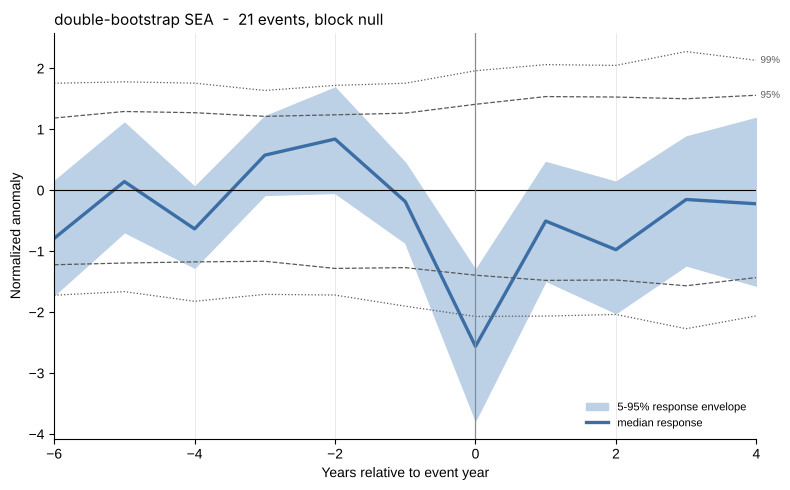

In [21]:
fig = res.plot(show=False)

The composite drops at lag 0 (the fire year) relative to the surrounding
years, consistent with fires occurring in drought years.

---

### The `dpl.fhx` namespace

| area | functions |
|---|---|
| I/O & model | `dpl.fhx.read`, `dpl.fhx.write`, `dpl.fhx.frame`, `dpl.fhx.as_frame`, `dpl.fhx.is_fhx` |
| accessors | `dpl.fhx.events`, `dpl.fhx.sort` (otherwise it's a plain DataFrame — use pandas) |
| statistics | `dpl.fhx.stats`, `dpl.fhx.summary`, `dpl.fhx.sample_depth`, `dpl.fhx.percent_scarred` |
| compositing | `dpl.fhx.composite` |
| intervals | `dpl.fhx.intervals` → `dpl.fhx.Intervals` (`.plot()`) |
| plots | `dpl.fhx.demograph` |
| fire–climate | `dpl.sea(climate, composite)` |

All results were validated against burnr. Faceting in `dpl.fhx.demograph` and
burnr's EVENT-style SEA are possible future additions.